## Import Libraries

In [1]:
!pip install seaborn  

In [2]:
!pip install torch 

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import sys
import os
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# PyTorch imports
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Add parent directory to path to import model
sys.path.insert(0, os.path.abspath('../..'))
from src.models.cnn import SeismicCNN, CompactSeismicCNN
from src.data.preprocessing import DataAugmentation
from src.data.labels import LABEL_MAP, MODEL_CLASSES, select_classes, infer_classes

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# Set up plotting
plt.style.use('seaborn-v0_8')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

print("\n✓ Libraries imported successfully!")

Using device: cuda
GPU: NVIDIA GeForce RTX 3090

✓ Libraries imported successfully!


## Load Labeled Data

Load the windowed seismograms and labels created by the labeling notebooks.

**Data Sources:**
- **AK Network**: High-quality professional seismic data (Alaska Seismic Network)
- **Catalog (AM)**: Raspberry Shake citizen science data with verified earthquake catalog
- **Rule-based**: Rule-based labeling from multi-class labeling notebook

In [4]:
# =============================================================================
# DATA SOURCE SELECTION
# Options: 'ak', 'catalog', or 'rule_based'
#   - 'ak': High-quality AK network data (professional seismic stations)
#   - 'catalog': AM network (Raspberry Shake) with verified earthquake catalog
#   - 'rule_based': Rule-based labeled data
# =============================================================================
DATA_SOURCE = 'ak'  # <-- CHANGE THIS: 'ak', 'catalog', 'rule_based', or a file prefix such as 'AM_traffic'

# Extra file sets to append to DATA_SOURCE, by prefix or glob pattern, e.g.
# ['AM_traffic_*', 'AK_train_*', 'AM_aircraft_*'] for the station-days written by
# scripts/collect_continuous_windows.py (one prefix per local day). Labels are
# global integers (src/data/labels.py) in every set, so they concatenate
# directly; MODEL_CLASSES_KEY below picks the subset the model trains on.
EXTRA_SOURCES = ['AM_traffic_*', 'AK_train_*', 'AK_trainnorth_*', 'AM_aircraft_*', 'AK_quiet_*']  # AM_traffic_* = the traffic week (configs/am_stations.yaml); it contains the two Romig days  # <-- e.g. ['AM_traffic_*', 'AK_train_*']

data_dir = Path("../02_labeling/labeled_data")

if not data_dir.exists():
    raise FileNotFoundError(f"Data directory '{data_dir}' not found. Run labeling notebooks first.")

# Find available data files based on selected source
if DATA_SOURCE == 'ak':
    # Use AK network data (high-quality professional seismic data)
    waveform_files = sorted(data_dir.glob("AK_waveforms_*.npy"))
    label_files = sorted(data_dir.glob("AK_labels_*.npy"))
    metadata_files = sorted(data_dir.glob("AK_metadata_*.csv"))
    data_source_name = "AK NETWORK (High-Quality Professional Seismic Data)"
elif DATA_SOURCE == 'catalog':
    # Use earthquake catalog data (AM/Raspberry Shake with verified ground truth)
    waveform_files = sorted(data_dir.glob("catalog_waveforms_*.npy"))
    label_files = sorted(data_dir.glob("catalog_labels_*.npy"))
    metadata_files = sorted(data_dir.glob("catalog_metadata_*.csv"))
    data_source_name = "CATALOG (AM Network - Raspberry Shake with Verified Catalog)"
elif DATA_SOURCE == 'rule_based':
    # Use rule-based labeled data
    waveform_files = sorted(data_dir.glob("windowed_waveforms_*.npy"))
    label_files = sorted(data_dir.glob("labels_*.npy"))
    metadata_files = sorted(data_dir.glob("metadata_*.csv"))
    data_source_name = "RULE-BASED LABELING"
else:
    # Any other value is a file prefix (scripts/collect_continuous_windows.py output)
    waveform_files = sorted(data_dir.glob(f"{DATA_SOURCE}_waveforms_*.npy"))
    label_files = sorted(data_dir.glob(f"{DATA_SOURCE}_labels_*.npy"))
    metadata_files = sorted(data_dir.glob(f"{DATA_SOURCE}_metadata_*.csv"))
    data_source_name = f"PREFIX {DATA_SOURCE}"

if not waveform_files or not label_files:
    raise FileNotFoundError(f"No {DATA_SOURCE} data found. Run the appropriate labeling notebook first:\n"
                          f"  - For AK data: run download_AK_only_data.ipynb\n"
                          f"  - For catalog data: run download_earthquake_catalog.ipynb\n"
                          f"  - For rule-based: run multi_class_labeling.ipynb")

def matching_files(waveform_files, label_files, metadata_files):
    """Newest waveforms file plus the labels/metadata that share its timestamp stamp."""
    wf = waveform_files[-1]
    stamp = wf.stem.split('_waveforms_')[-1]
    lf = [f for f in label_files if f.stem.endswith(stamp)]
    mf = [f for f in metadata_files if f.stem.endswith(stamp)]
    if not lf:
        raise FileNotFoundError(f"No labels file with stamp {stamp} next to {wf.name}")
    return wf, lf[0], (mf[0] if mf else None)

# Use the most recent run (all three files from the same stamp)
waveforms_file, labels_file, metadata_file = matching_files(waveform_files, label_files, metadata_files)

print(f"=" * 70)
print(f"DATA SOURCE: {data_source_name}")
print(f"=" * 70)
print(f"\nLoading data from:")
print(f"  Waveforms: {waveforms_file.name}")
print(f"  Labels: {labels_file.name}")
if metadata_file:
    print(f"  Metadata: {metadata_file.name}")

def load_waveforms(path):
    """Fixed-shape float arrays load without pickle; only ragged AK sets need it."""
    try:
        return np.load(path)
    except ValueError:  # object array (variable-length windows)
        return np.load(path, allow_pickle=True)

# Load data
X = load_waveforms(waveforms_file)  # (n_samples, window_length), or ragged object array for AK
y = np.load(labels_file)            # (n_samples,) integer labels, never pickled

if metadata_file:
    metadata = pd.read_csv(metadata_file)
    metadata['source_file'] = waveforms_file.name   # recorded in the split manifest
    metadata['source_row'] = np.arange(len(metadata))
else:
    metadata = None

# Append extra file sets (latest stamp of each prefix). X becomes a list of
# windows so fixed-length and ragged sets mix; cell 8 crops everything to 6000.
def expand_prefixes(patterns):
    """'AM_traffic_*' -> every prefix with waveform files matching it, newest stamp per prefix handled below."""
    out = []
    for pat in patterns:
        if '*' in pat or '?' in pat:
            found = sorted({f.stem.split('_waveforms_')[0] for f in data_dir.glob(f"{pat}_waveforms_*.npy")})
            if not found:
                raise FileNotFoundError(f"No file sets match '{pat}' in {data_dir}")
            out += found
        else:
            out.append(pat)
    return list(dict.fromkeys(out))  # overlapping patterns must not append a set twice

for prefix in expand_prefixes(EXTRA_SOURCES):
    wfs = sorted(data_dir.glob(f"{prefix}_waveforms_*.npy"))
    lfs = sorted(data_dir.glob(f"{prefix}_labels_*.npy"))
    mfs = sorted(data_dir.glob(f"{prefix}_metadata_*.csv"))
    if not wfs or not lfs:
        raise FileNotFoundError(f"No files for prefix '{prefix}' in {data_dir}")
    wf_x, lf_x, mf_x = matching_files(wfs, lfs, mfs)
    X_extra = load_waveforms(wf_x)
    y_extra = np.load(lf_x)
    print(f"  + {wf_x.name}: {len(y_extra)} windows")
    # Keep metadata rows aligned with X/y: a set without metadata contributes
    # empty rows so metadata.iloc[i] always refers to window i.
    n_before = len(y)
    if metadata is None:
        metadata = pd.DataFrame(index=range(n_before))
    meta_extra = pd.read_csv(mf_x) if mf_x else pd.DataFrame(index=range(len(y_extra)))
    meta_extra['source_file'] = wf_x.name
    meta_extra['source_row'] = np.arange(len(meta_extra))
    metadata = pd.concat([metadata, meta_extra], ignore_index=True)
    X = list(X) + list(X_extra)
    y = np.concatenate([np.asarray(y), np.asarray(y_extra)])
    assert len(metadata) == len(y), f"metadata rows {len(metadata)} != windows {len(y)}"
if EXTRA_SOURCES:
    X = np.array(X, dtype=object) if any(len(w) != len(X[0]) for w in X) else np.stack(X)

print(f"\n✓ Data loaded successfully!")
print(f"  X shape: {X.shape}")
print(f"  y shape: {y.shape}")

# Print class distribution
# Global label integers on disk (src/data/labels.py): 0 Noise, 1 Traffic,
# 2 Earthquake, 3 Avalanche, 4 Train, 5 Aircraft. The model's own class
# subset is chosen below with MODEL_CLASSES_KEY.
unique, counts = np.unique(y, return_counts=True)
print(f"\nClass distribution (global labels):")
for label, count in zip(unique, counts):
    print(f"  {LABEL_MAP[int(label)]} (label {int(label)}): {count} samples ({count/len(y)*100:.1f}%)")

# Show additional info for catalog/AK data
if metadata is not None and 'station' in metadata.columns:
    print(f"\nDataset diversity:")
    if 'event_id' in metadata.columns:
        print(f"  Unique earthquakes: {metadata['event_id'].nunique()}")
    print(f"  Unique stations: {metadata['station'].nunique()}")
    if 'network' in metadata.columns:
        print(f"  Network: {metadata['network'].unique().tolist()}")
    if 'channel' in metadata.columns:
        print(f"  Channels: {metadata['channel'].unique().tolist()}")
    if 'magnitude' in metadata.columns and metadata['magnitude'].notna().any():
        print(f"  Magnitude range: M{metadata['magnitude'].min():.1f} - M{metadata['magnitude'].max():.1f}")
    if 'label_method' in metadata.columns:
        print(f"  Label methods: {metadata['label_method'].dropna().unique().tolist()}")

DATA SOURCE: AK NETWORK (High-Quality Professional Seismic Data)

Loading data from:
  Waveforms: AK_waveforms_20260916_142515.npy
  Labels: AK_labels_20260916_142515.npy
  Metadata: AK_metadata_20260916_142515.csv


  + AM_traffic_2026-09-07_waveforms_20260930_100125.npy: 2198 windows
  + AM_traffic_2026-09-08_waveforms_20260930_100730.npy: 2700 windows
  + AM_traffic_2026-09-09_waveforms_20260930_101331.npy: 2669 windows
  + AM_traffic_2026-09-10_waveforms_20260930_101948.npy: 2688 windows
  + AM_traffic_2026-09-11_waveforms_20260930_102558.npy: 2680 windows
  + AM_traffic_2026-09-12_waveforms_20260930_103203.npy: 1317 windows
  + AM_traffic_2026-09-13_waveforms_20260930_103754.npy: 1325 windows
  + AK_train_2026-05-15_waveforms_20261022_111237.npy: 120 windows
  + AK_train_2026-05-16_waveforms_20261022_111252.npy: 155 windows
  + AK_train_2026-05-17_waveforms_20261022_111308.npy: 159 windows
  + AK_train_2026-05-18_waveforms_20261022_111323.npy: 122 windows
  + AK_train_2026-05-19_waveforms_20261022_111337.npy: 194 windows
  + AK_train_2026-05-20_waveforms_20261022_111351.npy: 117 windows
  + AK_train_2026-05-21_waveforms_20261022_111406.npy: 108 windows
  + AK_train_2026-05-22_waveforms_2026102

## Prepare Data for Training

Split data into train/validation/test sets and create PyTorch DataLoaders.

### Updated: Adds random splitting of larger earthquake files for data augmentation.

In [5]:
# ── Expand ragged windows into fixed 6000-sample training segments ───────────
# Per EQ window: N_ONSET_CROPS random crops guaranteed to contain the P arrival
# (start ≤ P), plus N_FREE_CROPS from anywhere in the window (may be coda-only),
# so the model sees both onsets and ongoing shaking. Noise passes through once.
N_ONSET_CROPS  = 1
N_FREE_CROPS   = 1
TARGET_LEN     = 6000
SAMPLING_RATE  = 100
rng = np.random.default_rng(42)

X_list, y_list, src_idx, crop_start = [], [], [], []
for i, w in enumerate(X):
    w = np.asarray(w, dtype=np.float32)
    slack = len(w) - TARGET_LEN
    if slack == 0:                                # noise: pass through
        starts = [0]
    else:                                         # EQ: 2 onset + 1 free
        p_off = metadata['p_offset_sec'].iloc[i] if 'p_offset_sec' in metadata.columns else None
        if pd.isna(p_off):
            raise ValueError(f"window {i} is {len(w)} samples with no p_offset_sec; "
                             "only AK earthquake windows may be longer than TARGET_LEN")
        p_sample = int(round(p_off * SAMPLING_RATE))
        onset_hi = min(p_sample, slack)
        starts = np.concatenate([
            rng.integers(0, onset_hi + 1, size=N_ONSET_CROPS),
            rng.integers(0, slack + 1,    size=N_FREE_CROPS),
        ])
    for s in starts:
        c = w[s:s + TARGET_LEN]
        c = (c - c.mean()) / (c.std() + 1e-10)
        X_list.append(c)
        y_list.append(y[i])
        src_idx.append(i)
        crop_start.append(int(s))

X = np.stack(X_list)          # (n_crops, 6000)
y = np.array(y_list)
src_idx = np.array(src_idx)   # crop -> original window row (indexes metadata)
crop_start = np.array(crop_start)  # crop -> start sample within its window
print(f"Expanded to X {X.shape} | " + ", ".join(f"{LABEL_MAP[int(k)]}: {(y==k).sum()}" for k in np.unique(y)))
print(f"Expanded to Y {y.shape}")

Expanded to X (57121, 6000) | Noise: 37502, Traffic: 15563, Earthquake: 2048, Train: 1029, Aircraft: 979
Expanded to Y (57121,)


In [6]:
# Add channel dimension for CNN: (n_samples, window_length) -> (n_samples, 1, window_length)
X = X[:, np.newaxis, :]  # Add channel dimension

print(f"Reshaped X: {X.shape}")

# Split manifest: one row per crop, marked as the pipeline drops or assigns it,
# written to datasets/splits/ so every run can be rebuilt and checked.
manifest = metadata.iloc[src_idx].reindex(columns=['source_file', 'source_row', 'network', 'station',
                                                   'channel', 'start_time', 'event_id', 'label_name']).reset_index(drop=True)
manifest['crop_start_sec'] = crop_start / SAMPLING_RATE
manifest['split'] = ''
row = np.arange(len(manifest))  # crop -> manifest row, filtered along with X and y

# =============================================================================
# MODEL CLASS SUBSET
# Pick which classes this model separates. Windows with other labels are
# dropped and the kept labels are remapped to contiguous 0..K-1 (required by
# CrossEntropyLoss). Options (src/data/labels.py MODEL_CLASSES):
#   'earthquake'    Noise / Earthquake                  <- deployed compact-v2
#   'natural'       Noise / Earthquake / Avalanche      <- CLUE "Natural" model
#   'human'         Noise / Train / Aircraft            <- CLUE "Human" model
#   'human_traffic' Noise / Traffic / Train / Aircraft
#   'rule_based'    Noise / Traffic / Earthquake
# or an explicit list such as ['Noise', 'Earthquake'].
# =============================================================================
MODEL_CLASSES_KEY = "human_traffic" # <-- CHANGE THIS
from src.data.labels import class_subset, global_labels

# =============================================================================
# TRAFFIC CAP
# The traffic week gives ~900-1,600 Traffic windows per Raspberry Shake station,
# about twice the capped Noise class. Cap Traffic per station the same way
# (seeded, random within each station) so it doesn't swamp the other classes.
# None keeps every Traffic window.
# =============================================================================
TRAFFIC_MAX_PER_STATION = 300  # <-- CHANGE THIS

if TRAFFIC_MAX_PER_STATION is not None and metadata is not None and 'station' in metadata.columns:
    traffic_label = 1  # global label integer for Traffic (src/data/labels.py)
    station = metadata['station'].to_numpy()[src_idx]
    keep = np.ones(len(y), dtype=bool)
    rng_traffic = np.random.default_rng(42)
    for sta in np.unique(station):
        idx = np.flatnonzero((y == traffic_label) & (station == sta))
        if len(idx) > TRAFFIC_MAX_PER_STATION:
            keep[rng_traffic.choice(idx, len(idx) - TRAFFIC_MAX_PER_STATION, replace=False)] = False
    n_before = int((y == traffic_label).sum())
    manifest.loc[row[~keep], 'split'] = 'dropped_traffic_cap'
    X, y, src_idx, row = X[keep], y[keep], src_idx[keep], row[keep]
    print(f"Traffic capped at {TRAFFIC_MAX_PER_STATION} per station: {n_before} -> {int((y == traffic_label).sum())} windows")
    print("  per station: " + ", ".join(f"{s} {n}" for s, n in
          pd.Series(station[keep][y == traffic_label]).value_counts().sort_index().items()))

# =============================================================================
# NOISE CAP
# Noise comes from every set, and K222's quiet hours alone give ~8,800
# windows against ~700 Train. Cap Noise per station (seeded) so no single
# site or instrument dominates the class. Only Noise is capped here.
# None keeps every Noise window.
# With NOISE_MATCH_TRAFFIC, a station that also gives Traffic keeps as much
# Noise as its (capped) Traffic, so the site alone does not predict the class
# (at 150 Noise / 300 Traffic every Shake traffic site was 2:1 Traffic).
# Only when the model has a Traffic class.
# =============================================================================
NOISE_MAX_PER_STATION = 150  # <-- CHANGE THIS
NOISE_MATCH_TRAFFIC = True   # <-- CHANGE THIS

if NOISE_MAX_PER_STATION is not None and metadata is not None and 'station' in metadata.columns:
    noise_label = 0  # global label integer for Noise (src/data/labels.py)
    station = metadata['station'].to_numpy()[src_idx]
    keep = np.ones(len(y), dtype=bool)
    rng_noise = np.random.default_rng(42)
    match_traffic = NOISE_MATCH_TRAFFIC and 'Traffic' in class_subset(MODEL_CLASSES_KEY)
    for sta in np.unique(station):
        idx = np.flatnonzero((y == noise_label) & (station == sta))
        cap = NOISE_MAX_PER_STATION
        if match_traffic:  # the Traffic cap has already run
            cap = max(cap, int(((y == 1) & (station == sta)).sum()))  # 1 = Traffic (global label)
        if len(idx) > cap:
            keep[rng_noise.choice(idx, len(idx) - cap, replace=False)] = False
    n_before = int((y == noise_label).sum())
    manifest.loc[row[~keep], 'split'] = 'dropped_noise_cap'
    X, y, src_idx, row = X[keep], y[keep], src_idx[keep], row[keep]
    print(f"Noise capped at {NOISE_MAX_PER_STATION} per station{' (Traffic stations matched 1:1)' if match_traffic else ''}: {n_before} -> {int((y == noise_label).sum())} windows")
    print("  per station: " + ", ".join(f"{s} {n}" for s, n in
          pd.Series(station[keep][y == noise_label]).value_counts().sort_index().items()))

# =============================================================================
# MODEL CLASS SUBSET (applied here; MODEL_CLASSES_KEY is set above the caps)
# =============================================================================
print(f"Global labels in data: {infer_classes(y)}")
# select_classes does not return its mask; rebuild it so src_idx and row stay aligned with X
class_keep = np.isin(y, global_labels(class_subset(MODEL_CLASSES_KEY)))
manifest.loc[row[~class_keep], 'split'] = 'dropped_class'
src_idx, row = src_idx[class_keep], row[class_keep]
X, y, class_names = select_classes(X, y, MODEL_CLASSES_KEY)
print(f"Model classes ({MODEL_CLASSES_KEY}): {class_names}")
print(f"Remapped labels: {np.unique(y)} -> {X.shape[0]} windows kept")


# =============================================================================
# GROUPED SPLIT
# Crops that share a source cannot be split apart: every crop and station of
# one earthquake (and its pre-P Noise) is one group; every continuous window
# from one station on one local day is one group. Test and validation are
# each about 10% of groups, stratified by class, so both are unseen events
# and station-days.
# =============================================================================
from sklearn.model_selection import StratifiedGroupKFold

m = metadata.iloc[src_idx]
local_day = pd.to_datetime(m['start_time'], utc=True).dt.tz_convert('America/Anchorage').dt.date.astype(str)
event_id = m['event_id'] if 'event_id' in m.columns else pd.Series(np.nan, index=m.index)
# Only catalog earthquakes group by event: K222 train windows also carry an
# event_id (the timetable passage), but they are grouped by station-day.
from_catalog = m['label_method'].astype(str).str.startswith('comcat')
has_event = from_catalog & event_id.notna() & (event_id.astype(str).str.strip() != '')
groups = np.where(has_event, 'event:' + event_id.astype(str),
                  m['station'].astype(str) + ':' + local_day).astype(str)

def one_fold(y, groups, n_splits):
    """Indices (rest, held) of the first fold of a seeded StratifiedGroupKFold."""
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=42)
    return next(sgkf.split(np.zeros(len(y)), y, groups))

rest, test = one_fold(y, groups, 10)               # ~10% of groups -> test
tr, va = one_fold(y[rest], groups[rest], 9)        # ~10% of the total -> validation
train, val = rest[tr], rest[va]

for a, b in [(train, val), (train, test), (val, test)]:
    assert not set(groups[a]) & set(groups[b]), "a group landed in two splits"
for split_name, idx in [('train', train), ('val', val), ('test', test)]:
    missing = set(range(len(class_names))) - set(y[idx])
    assert not missing, (f"{split_name} has no {[class_names[k] for k in missing]}: too few groups for that "
                         "class (Traffic needs the week set, configs/am_stations.yaml)")
    manifest.loc[row[idx], 'split'] = split_name
    manifest.loc[row[idx], 'group'] = groups[idx]

X_train, y_train = X[train], y[train]
X_val, y_val = X[val], y[val]
X_test, y_test = X[test], y[test]

# One manifest per run, shared by both architectures (its path goes into each checkpoint)
RUN_STAMP = datetime.now().strftime('%Y%m%d_%H%M%S')
split_manifest_path = Path('../../datasets/splits') / f'split_{RUN_STAMP}.csv'
split_manifest_path.parent.mkdir(parents=True, exist_ok=True)
manifest.to_csv(split_manifest_path, index_label='crop_id')
print(f"Split manifest: {split_manifest_path}")
print("Groups per split: " + ", ".join(f"{n} {len(set(groups[i]))}" for n, i in
                                      [('train', train), ('val', val), ('test', test)]))

print(f"\nData split:")
print(f"  Train: {X_train.shape[0]} samples ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"  Val:   {X_val.shape[0]} samples ({X_val.shape[0]/len(X)*100:.1f}%)")
print(f"  Test:  {X_test.shape[0]} samples ({X_test.shape[0]/len(X)*100:.1f}%)")

# Print class distribution per split
for split_name, y_split in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
    print(f"\n{split_name} class distribution:")
    unique, counts = np.unique(y_split, return_counts=True)
    for label, count in zip(unique, counts):
        print(f"  {class_names[int(label)]}: {count} ({count/len(y_split)*100:.1f}%)")

# Data augmentation setting (will be overridden in config cell if needed)
use_augmentation = True  # Enable data augmentation for training
batch_size = 32  # Default batch size (can be overridden in config cell)

# Create custom dataset with augmentation for training
class AugmentedDataset(Dataset):
    """Dataset that applies augmentation during training."""
    def __init__(self, X, y, augment=None):
        self.X = torch.FloatTensor(X)
        self.y = torch.LongTensor(y)
        self.augment = augment
    
    def __len__(self):
        return len(self.y)
    
    def __getitem__(self, idx):
        x = self.X[idx]  # Shape: [1, 500] or [channels, length]
        y = self.y[idx]
        
        # Apply augmentation if provided (only during training)
        if self.augment is not None:
            # Convert to numpy, augment, convert back
            x_np = x.numpy()  # Shape: (1, 500) or (channels, length)
            x_aug = self.augment(x_np)  # Should preserve shape (1, 500)
            # Ensure x_aug is 2D: (channels, length)
            if x_aug.ndim == 1:
                x_aug = x_aug[np.newaxis, :]  # Add channel dimension
            elif x_aug.ndim == 3:
                x_aug = x_aug.squeeze(0)  # Remove batch dimension if present
            # Convert back to tensor with explicit shape preservation
            x = torch.from_numpy(x_aug).float()
            # Final shape check: should be [channels, length]
            assert x.dim() == 2, f"Expected 2D tensor, got {x.dim()}D with shape {x.shape}"
        
        return x, y

# Create augmentation transform for training data
if use_augmentation:
    # Moderate augmentation: small noise, small time shifts, slight amplitude scaling
    aug_transform = DataAugmentation(
        noise_level=0.02,  # 2% noise
        time_shift_range=25,  # Small time shifts (25 samples = 0.25s at 100Hz)
        amplitude_scale_range=(0.9, 1.1)  # ±10% amplitude variation
    )
    print("✓ Data augmentation enabled for training")
else:
    aug_transform = None

# Create datasets
train_dataset = AugmentedDataset(X_train, y_train, augment=aug_transform)
val_dataset = TensorDataset(torch.FloatTensor(X_val), torch.LongTensor(y_val))
test_dataset = TensorDataset(torch.FloatTensor(X_test), torch.LongTensor(y_test))

# Create dataloaders
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"\n✓ DataLoaders created with batch size: {batch_size}")
print(f"  Train batches: {len(train_loader)}")
print(f"  Val batches: {len(val_loader)}")
print(f"  Test batches: {len(test_loader)}")

Reshaped X: (57121, 1, 6000)
Traffic capped at 300 per station: 15563 -> 2700 windows
  per station: K222 300, R1796 300, R2A1A 300, R3130 300, R4017 300, R9286 300, R9EA1 300, RF528 300, RFD97 300
Noise capped at 150 per station (Traffic stations matched 1:1): 37502 -> 3600 windows
  per station: FIRE 150, K217 150, K220 150, K222 300, MS01 150, R1796 300, R2A1A 300, R3130 300, R4017 300, R9286 300, R9EA1 300, RC01 150, RF528 300, RFD97 300, SSN 150
Global labels in data: ['Noise', 'Traffic', 'Earthquake', 'Train', 'Aircraft']
Model classes (human_traffic): ['Noise', 'Traffic', 'Train', 'Aircraft']
Remapped labels: [0 1 2 3] -> 8308 windows kept
Split manifest: ../../datasets/splits/split_20261026_130204.csv
Groups per split: train 552, val 69, test 71

Data split:
  Train: 6673 samples (80.3%)
  Val:   708 samples (8.5%)
  Test:  927 samples (11.2%)

Train class distribution:
  Noise: 2879 (43.1%)
  Traffic: 2213 (33.2%)
  Train: 820 (12.3%)
  Aircraft: 761 (11.4%)

Val class distrib

## Configuration

Configure training parameters and models to train.


In [7]:
# Model configuration
num_classes = len(class_names)  # Automatically set based on data (2 or 3 classes)
input_channels = 1  # Single channel (vertical component)
input_length = X_train.shape[2]  # Window length in samples

print(f"Model configuration:")
print(f"  Input channels: {input_channels}")
print(f"  Input length: {input_length} samples")
print(f"  Number of classes: {num_classes}")
print(f"  Class names: {class_names}")

# Training hyperparameters - Different settings for each model
# Standard model was UNDERFITTING (88% train, 87% val) - need to allow it to learn more
learning_rates = {
    'compact': 0.0005,   # Keep stable
    'standard': 0.0004   # Increased from 0.0002 - was too low, preventing learning
}
weight_decay = 1e-3  # Reduced from 1.5e-3 - was too aggressive
batch_size = 32  # Override default from cell 7 if needed
num_epochs = 60  # Allow more epochs, early stopping will prevent overfitting
max_grad_norm = 2.0  # Increased from 1.0 - allow more gradient flow for learning
# use_augmentation is defined in cell 7 (data preparation)

# Early stopping parameters
early_stopping_patience = 10  # Stop if no improvement for 10 epochs
early_stopping_min_delta = 0.001  # Minimum change to qualify as improvement

# Models to train
models_to_train = ['compact', 'standard']  # Train both models

# Folder each architecture's weights go to (models/<id>/). Written into the
# checkpoint and the summary, so every run names the model it produced.
MODEL_IDS = {'compact': 'compact-v4', 'standard': 'standard-v3'}  # <-- CHANGE THIS

print(f"\nTraining configuration:")
print(f"  Epochs: {num_epochs} (with early stopping)")
print(f"  Learning rates: {learning_rates}")
print(f"  Weight decay: {weight_decay}")
print(f"  Batch size: {batch_size}")
print(f"  Max gradient norm: {max_grad_norm} (gradient clipping)")
print(f"  Data augmentation: {use_augmentation}")
print(f"  Early stopping patience: {early_stopping_patience}")
print(f"\n✓ Will train {len(models_to_train)} models: {', '.join(models_to_train)}")


Model configuration:
  Input channels: 1
  Input length: 6000 samples
  Number of classes: 4
  Class names: ['Noise', 'Traffic', 'Train', 'Aircraft']

Training configuration:
  Epochs: 60 (with early stopping)
  Learning rates: {'compact': 0.0005, 'standard': 0.0004}
  Weight decay: 0.001
  Batch size: 32
  Max gradient norm: 2.0 (gradient clipping)
  Data augmentation: True
  Early stopping patience: 10

✓ Will train 2 models: compact, standard


## Training Loop for Both Models

Train both compact and standard models, saving each one separately.


In [8]:
import copy
import subprocess
import time

# Define num_classes based on class_names (should be defined from Cell 7)
# This accounts for the 2-class dataset (Noise, Earthquake) after remapping
num_classes = len(class_names)  # Automatically set based on data (2 or 3 classes)
print(f"Number of classes: {num_classes}")
print(f"Class names: {class_names}")

# Loss function (with class weights for imbalanced data)
# Count samples per class (only classes that exist in the data)
class_counts = np.bincount(y_train, minlength=num_classes)

# Check for empty classes and handle gracefully
print(f"Class counts in training data:")
for i, (name, count) in enumerate(zip(class_names, class_counts)):
    print(f"  {name}: {count}")

# Compute inverse frequency weights (avoid division by zero)
class_weights = np.zeros(num_classes)
for i in range(num_classes):
    if class_counts[i] > 0:
        class_weights[i] = 1.0 / class_counts[i]
    else:
        class_weights[i] = 0.0  # No samples = no weight

# Normalize weights
if class_weights.sum() > 0:
    class_weights = class_weights / class_weights.sum() * num_classes
    
class_weights_tensor = torch.FloatTensor(class_weights).to(device)

print(f"\nClass weights for loss function:")
for i, (name, weight) in enumerate(zip(class_names, class_weights)):
    print(f"  {name}: {weight:.3f}")


def train_epoch(model, train_loader, criterion, optimizer, device, max_grad_norm=1.0):
    """Train for one epoch with gradient clipping."""
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        
        # Gradient clipping to prevent spikes
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
        
        optimizer.step()
        
        running_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    
    return running_loss / total, 100 * correct / total


def validate_epoch(model, val_loader, criterion, device):
    """Validate for one epoch."""
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    
    return running_loss / total, 100 * correct / total


def train_model(model, model_type, train_loader, val_loader, criterion, num_epochs, learning_rate, weight_decay, device, patience=10, min_delta=0.001, max_grad_norm=1.0):
    """Train a model and return history and best state."""
    optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    # Use ReduceLROnPlateau - adapts to validation loss, smoother than fixed steps
    # More aggressive: reduce LR faster when stuck, but allow lower minimum LR
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=4,  # Reduced patience from 5
        min_lr=1e-7,  # Lower minimum to allow fine-tuning
        cooldown=2  # Wait 2 epochs after LR reduction before checking again
    )
    
    history = {
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': []
    }
    
    best_val_loss = float('inf')
    best_model_state = copy.deepcopy(model.state_dict())  # Initialize with current state (never None)
    patience_counter = 0  # Early stopping counter
    
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    
    print(f"\n{'='*70}")
    print(f"Training {model_type.upper()} Model ({n_params:,} parameters)")
    print(f"{'='*70}")
    print(f"{'Epoch':<6} {'Train Loss':<12} {'Train Acc':<12} {'Val Loss':<12} {'Val Acc':<12} {'Time':<8}")
    print("-" * 70)
    
    for epoch in range(num_epochs):
        start_time = time.time()
        
        train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device, max_grad_norm)
        val_loss, val_acc = validate_epoch(model, val_loader, criterion, device)
        scheduler.step(val_loss)  # ReduceLROnPlateau needs validation loss
        
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        
        # Check for improvement
        improvement = (best_val_loss - val_loss) >= min_delta
        if improvement:
            best_val_loss = val_loss
            best_model_state = copy.deepcopy(model.state_dict())
            patience_counter = 0  # Reset counter on improvement
        else:
            patience_counter += 1
        
        epoch_time = time.time() - start_time
        status = "✓" if improvement else " "
        print(f"{epoch+1:<6} {train_loss:<12.4f} {train_acc:<12.2f} {val_loss:<12.4f} {val_acc:<12.2f} {epoch_time:<8.2f}s {status}")
        
        # Early stopping
        if patience_counter >= patience:
            print(f"\n⚠️  Early stopping triggered after {epoch+1} epochs (no improvement for {patience} epochs)")
            break
    
    print(f"\n✓ {model_type.capitalize()} model training complete!")
    print(f"  Best validation loss: {best_val_loss:.4f}")
    print(f"  Final train accuracy: {history['train_acc'][-1]:.2f}%")
    print(f"  Final val accuracy: {history['val_acc'][-1]:.2f}%")
    
    # Load best model
    model.load_state_dict(best_model_state)
    
    return history, best_val_loss, n_params


# Store results for all models
all_results = {}

# Create models directory
models_dir = Path("../../models")
models_dir.mkdir(exist_ok=True)

# Train each model
def git_state():
    """(commit, dirty) of the repo this notebook runs in; (None, None) outside git."""
    try:
        commit = subprocess.run(['git', 'rev-parse', 'HEAD'], capture_output=True, text=True, check=True).stdout.strip()
        dirty = bool(subprocess.run(['git', 'status', '--porcelain', '--untracked-files=no'],
                                    capture_output=True, text=True).stdout.strip())
        return commit, dirty
    except (OSError, subprocess.CalledProcessError):
        return None, None

# How this run was made: everything that is otherwise hand-edited in the cells above
git_commit, git_dirty = git_state()
provenance = {
    'data_source': DATA_SOURCE,
    'extra_sources': list(EXTRA_SOURCES),
    'model_classes_key': MODEL_CLASSES_KEY,
    'noise_max_per_station': NOISE_MAX_PER_STATION,
    'noise_match_traffic': NOISE_MATCH_TRAFFIC,
    'traffic_max_per_station': TRAFFIC_MAX_PER_STATION,
    'n_onset_crops': N_ONSET_CROPS,
    'n_free_crops': N_FREE_CROPS,
    'split_method': 'StratifiedGroupKFold by event_id (AK events) or station + local day, seed 42',
    'split_manifest': str(split_manifest_path.resolve().relative_to(Path('../..').resolve())),
    'split_sizes': {'train': len(y_train), 'val': len(y_val), 'test': len(y_test)},
    'git_commit': git_commit,
    'git_dirty': git_dirty,  # True: the notebook or code differed from that commit
}
print(f"Provenance: {provenance}")

for model_type in models_to_train:
    print(f"\n{'#'*70}")
    print(f"# TRAINING {model_type.upper()} MODEL")
    print(f"{'#'*70}\n")
    
    # Initialize model with appropriate dropout
    if model_type == 'standard':
        model = SeismicCNN(
            num_classes=num_classes,
            input_channels=input_channels,
            input_length=input_length,
            dropout_rate=0.4  # Reduced from 0.5 - was preventing learning (underfitting)
        )
    else:
        model = CompactSeismicCNN(
            num_classes=num_classes,
            input_channels=input_channels,
            input_length=input_length
        )
    
    model = model.to(device)
    
    # Create loss function for this model
    criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
    
    # Get model-specific learning rate
    model_lr = learning_rates[model_type]
    
    # Train the model
    history, best_val_loss, n_params = train_model(
        model, model_type, train_loader, val_loader, criterion,
        num_epochs, model_lr, weight_decay, device,
        patience=early_stopping_patience, min_delta=early_stopping_min_delta,
        max_grad_norm=max_grad_norm
    )
    
    # Evaluate on test set
    model.eval()
    y_true = []
    y_pred = []
    y_proba = []
    
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            probabilities = torch.softmax(outputs, dim=1)
            _, predicted = torch.max(outputs.data, 1)
            
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())
            y_proba.extend(probabilities.cpu().numpy())
    
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_proba = np.array(y_proba)
    
    test_accuracy = accuracy_score(y_true, y_pred)
    
    print(f"\n{model_type.capitalize()} Model Test Results:")
    print(f"  Test Accuracy: {test_accuracy*100:.2f}%")
    print(f"\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
    
    # Save model
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    model_filename = f"seismic_cnn_{model_type}_{DATA_SOURCE}_{timestamp}.pth"
    model_path = models_dir / model_filename
    
    torch.save({
        'model_state_dict': model.state_dict(),
        'model_type': model_type,
        'data_source': DATA_SOURCE,
        'num_classes': num_classes,
        'input_channels': input_channels,
        'input_length': input_length,
        'class_names': class_names,
        'test_accuracy': test_accuracy,
        'history': history,
        'model_id': MODEL_IDS[model_type],
        'provenance': provenance,
        'test_report': classification_report(y_true, y_pred, target_names=class_names, digits=4, output_dict=True),
        'training_config': {
            'num_epochs': num_epochs,
            'batch_size': batch_size,
            'learning_rate': model_lr,  # Model-specific learning rate
            'weight_decay': weight_decay
        }
    }, model_path)
    
    print(f"\n✓ Model saved to: {model_path}")
    
    # Store results
    all_results[model_type] = {
        'model': model,
        'history': history,
        'test_accuracy': test_accuracy,
        'n_params': n_params,
        'y_true': y_true,
        'y_pred': y_pred,
        'y_proba': y_proba,
        'model_path': model_path
    }
    
    # Small delay between models
    time.sleep(1)

print(f"\n{'='*70}")
print(f"ALL MODELS TRAINED SUCCESSFULLY!")
print(f"{'='*70}")


Number of classes: 4
Class names: ['Noise', 'Traffic', 'Train', 'Aircraft']
Class counts in training data:
  Noise: 2879
  Traffic: 2213
  Train: 820
  Aircraft: 761



Class weights for loss function:
  Noise: 0.417
  Traffic: 0.542
  Train: 1.464
  Aircraft: 1.577
Provenance: {'data_source': 'ak', 'extra_sources': ['AM_traffic_*', 'AK_train_*', 'AK_trainnorth_*', 'AM_aircraft_*', 'AK_quiet_*'], 'model_classes_key': 'human_traffic', 'noise_max_per_station': 150, 'noise_match_traffic': True, 'traffic_max_per_station': 300, 'n_onset_crops': 1, 'n_free_crops': 1, 'split_method': 'StratifiedGroupKFold by event_id (AK events) or station + local day, seed 42', 'split_manifest': 'datasets/splits/split_20261026_130204.csv', 'split_sizes': {'train': 6673, 'val': 708, 'test': 927}, 'git_commit': 'fc9784148cce1b3d3ff8b1e16c4e24ec544c5acd', 'git_dirty': True}

######################################################################
# TRAINING COMPACT MODEL
######################################################################


Training COMPACT Model (9,412 parameters)
Epoch  Train Loss   Train Acc    Val Loss     Val Acc      Time    
---------------------------

## Compare Model Performance

Visualize training history and compare both models side-by-side.


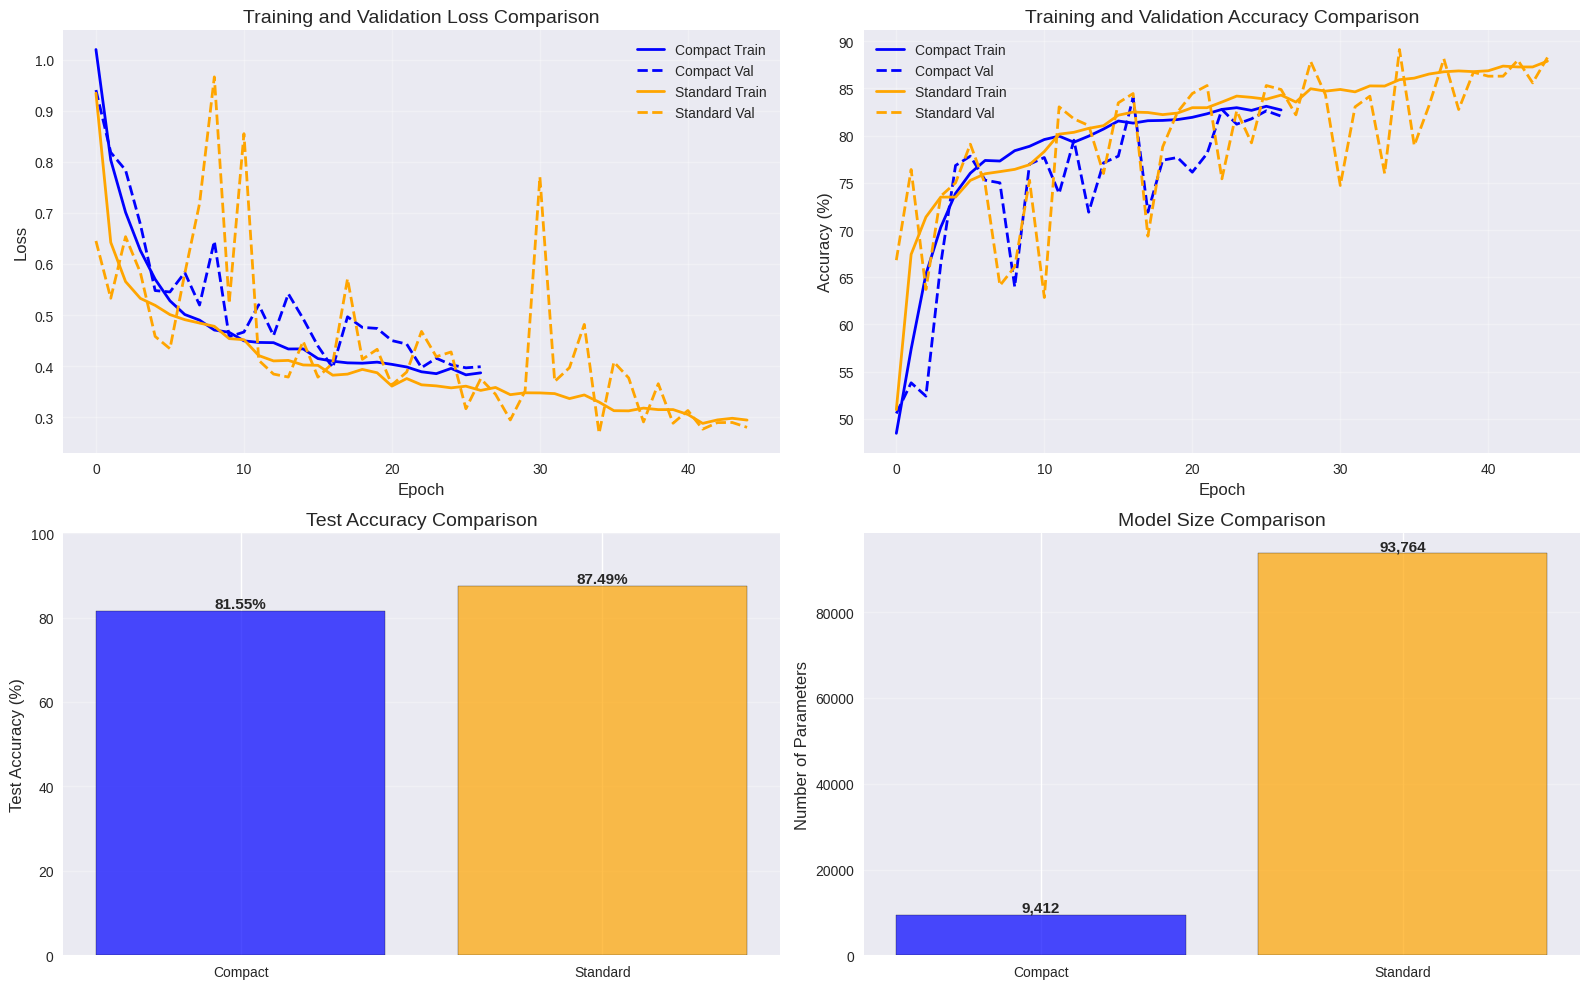


MODEL COMPARISON SUMMARY
Model           Parameters      Test Accuracy   Saved To                      
----------------------------------------------------------------------
Compact         9,412           81.55           seismic_cnn_compact_ak_20261026_130351.pth
Standard        93,764          87.49           seismic_cnn_standard_ak_20261026_130655.pth


In [9]:
# Plot training curves for both models
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

colors = {'compact': 'blue', 'standard': 'orange'}
line_styles = {'train': '-', 'val': '--'}

# Loss comparison
ax = axes[0, 0]
for model_type in models_to_train:
    history = all_results[model_type]['history']
    ax.plot(history['train_loss'], label=f'{model_type.capitalize()} Train', 
            color=colors[model_type], linestyle=line_styles['train'], linewidth=2)
    ax.plot(history['val_loss'], label=f'{model_type.capitalize()} Val', 
            color=colors[model_type], linestyle=line_styles['val'], linewidth=2)
ax.set_xlabel('Epoch', fontsize=12)
ax.set_ylabel('Loss', fontsize=12)
ax.set_title('Training and Validation Loss Comparison', fontsize=14)
ax.legend()
ax.grid(True, alpha=0.3)

# Accuracy comparison
ax = axes[0, 1]
for model_type in models_to_train:
    history = all_results[model_type]['history']
    ax.plot(history['train_acc'], label=f'{model_type.capitalize()} Train', 
            color=colors[model_type], linestyle=line_styles['train'], linewidth=2)
    ax.plot(history['val_acc'], label=f'{model_type.capitalize()} Val', 
            color=colors[model_type], linestyle=line_styles['val'], linewidth=2)
ax.set_xlabel('Epoch', fontsize=12)
ax.set_ylabel('Accuracy (%)', fontsize=12)
ax.set_title('Training and Validation Accuracy Comparison', fontsize=14)
ax.legend()
ax.grid(True, alpha=0.3)

# Model comparison bar chart - Test Accuracy
ax = axes[1, 0]
model_names = [m.capitalize() for m in models_to_train]
test_accs = [all_results[m]['test_accuracy'] * 100 for m in models_to_train]
params = [all_results[m]['n_params'] for m in models_to_train]

bars = ax.bar(model_names, test_accs, color=[colors[m] for m in models_to_train], alpha=0.7, edgecolor='black')
ax.set_ylabel('Test Accuracy (%)', fontsize=12)
ax.set_title('Test Accuracy Comparison', fontsize=14)
ax.set_ylim([0, 100])
ax.grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for bar, acc in zip(bars, test_accs):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{acc:.2f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')

# Model comparison - Parameters
ax = axes[1, 1]
bars = ax.bar(model_names, params, color=[colors[m] for m in models_to_train], alpha=0.7, edgecolor='black')
ax.set_ylabel('Number of Parameters', fontsize=12)
ax.set_title('Model Size Comparison', fontsize=14)
ax.grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for bar, param in zip(bars, params):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{param:,}', ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

# Print comparison summary
print("\n" + "="*70)
print("MODEL COMPARISON SUMMARY")
print("="*70)
print(f"{'Model':<15} {'Parameters':<15} {'Test Accuracy':<15} {'Saved To':<30}")
print("-"*70)
for model_type in models_to_train:
    result = all_results[model_type]
    print(f"{model_type.capitalize():<15} {result['n_params']:<15,} {result['test_accuracy']*100:<15.2f} {result['model_path'].name:<30}")
print("="*70)


## Confusion Matrices for Both Models

Compare confusion matrices to see how each model performs on different classes.


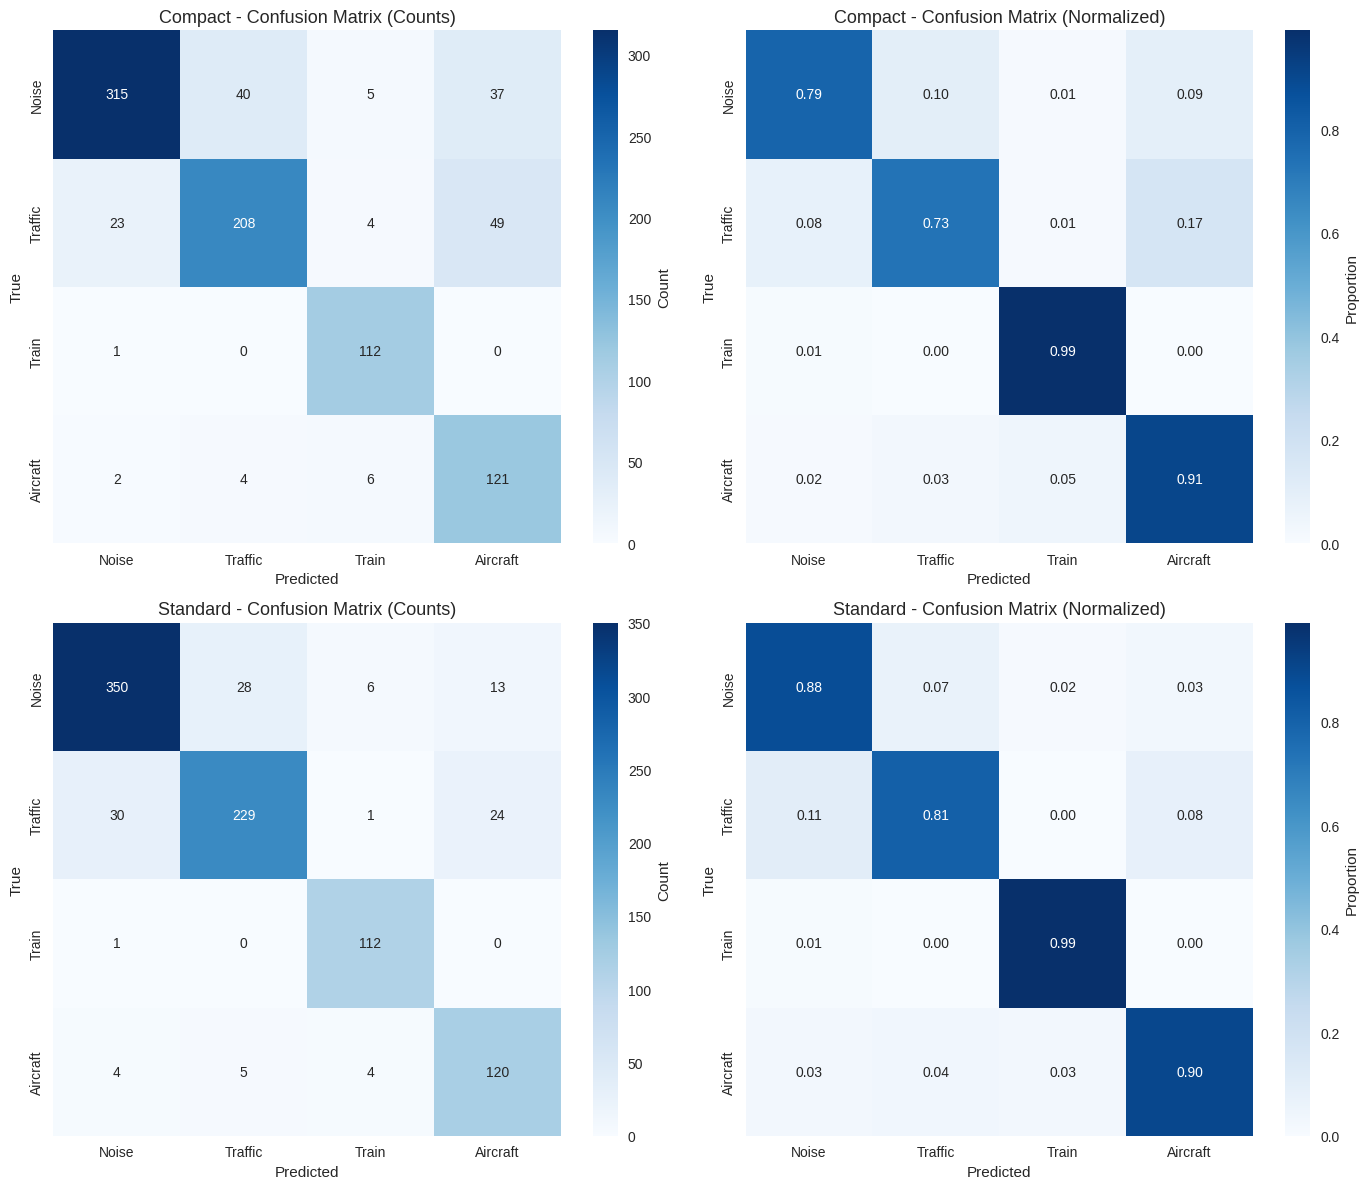

✓ Confusion matrices plotted for both models


In [10]:
# Plot confusion matrices for both models
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

for idx, model_type in enumerate(models_to_train):
    y_true = all_results[model_type]['y_true']
    y_pred = all_results[model_type]['y_pred']
    
    # Compute confusion matrices
    cm = confusion_matrix(y_true, y_pred)
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    
    # Raw counts
    ax = axes[idx, 0]
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, 
                yticklabels=class_names, ax=ax, cbar_kws={'label': 'Count'})
    ax.set_xlabel('Predicted', fontsize=11)
    ax.set_ylabel('True', fontsize=11)
    ax.set_title(f'{model_type.capitalize()} - Confusion Matrix (Counts)', fontsize=13)
    
    # Normalized
    ax = axes[idx, 1]
    sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues', xticklabels=class_names,
                yticklabels=class_names, ax=ax, cbar_kws={'label': 'Proportion'})
    ax.set_xlabel('Predicted', fontsize=11)
    ax.set_ylabel('True', fontsize=11)
    ax.set_title(f'{model_type.capitalize()} - Confusion Matrix (Normalized)', fontsize=13)

plt.tight_layout()
plt.show()

print("✓ Confusion matrices plotted for both models")


## Example Predictions

Visualize predictions from the compact model on test examples.


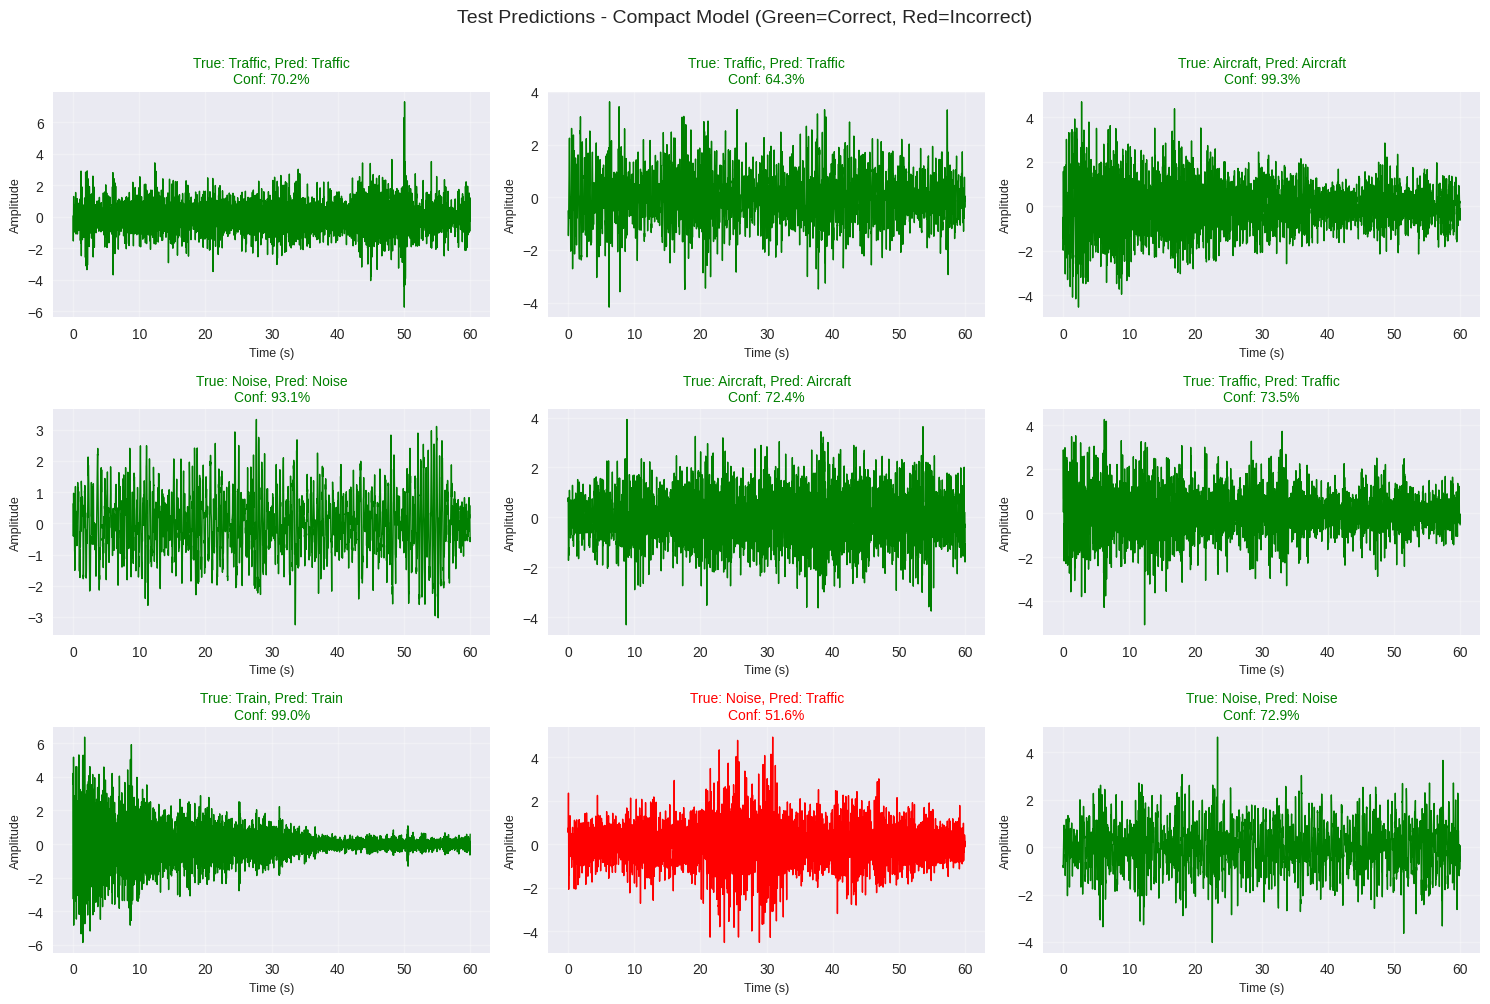

✓ Example predictions visualized


In [11]:
# Use compact model for visualization
model_type = 'compact'
y_pred = all_results[model_type]['y_pred']
y_proba = all_results[model_type]['y_proba']

# Select random examples from test set
n_examples = 9
random_indices = np.random.choice(len(X_test), n_examples, replace=False)

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()

for i, idx in enumerate(random_indices):
    ax = axes[i]
    
    # Get waveform
    waveform = X_test[idx, 0, :]  # Remove channel dimension
    true_label = y_test[idx]
    pred_label = y_pred[idx]
    proba = y_proba[idx]
    
    # Plot waveform
    time_axis = np.arange(len(waveform)) / 100.0  # Assuming 100 Hz
    color = 'green' if true_label == pred_label else 'red'
    ax.plot(time_axis, waveform, color=color, linewidth=1)
    
    # Title with prediction info
    title = f"True: {class_names[true_label]}, Pred: {class_names[pred_label]}\n"
    title += f"Conf: {proba[pred_label]*100:.1f}%"
    ax.set_title(title, fontsize=10, color=color)
    ax.set_xlabel('Time (s)', fontsize=9)
    ax.set_ylabel('Amplitude', fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle(f'Test Predictions - {model_type.capitalize()} Model (Green=Correct, Red=Incorrect)', 
             fontsize=14, y=1.00)
plt.tight_layout()
plt.show()

print("✓ Example predictions visualized")


## Training Summary

Both models have been saved. Review the final summary.


In [12]:
# Print final summary
print("="*70)
print("TRAINING COMPLETE - FINAL SUMMARY")
print("="*70)

for model_type in models_to_train:
    result = all_results[model_type]
    print(f"\n{model_type.upper()} MODEL:")
    print(f"  Parameters: {result['n_params']:,}")
    print(f"  Test Accuracy: {result['test_accuracy']*100:.2f}%")
    print(f"  Saved to: {result['model_path']}")
    
    # Save training summary
    timestamp = result['model_path'].stem.split('_')[-1]
    summary_file = models_dir / f"training_summary_{MODEL_IDS[model_type]}_{timestamp}.txt"
    
    with open(summary_file, 'w') as f:
        f.write(f"Seismic CNN Training Summary - {model_type.upper()} Model\n")
        f.write("="*60 + "\n\n")
        f.write(f"Date: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n\n")
        
        f.write("Model Configuration:\n")
        f.write(f"  Model id: {MODEL_IDS[model_type]}\n")
        f.write(f"  Checkpoint: {result['model_path'].name}\n")
        f.write(f"  Type: {model_type}\n")
        f.write(f"  Parameters: {result['n_params']:,}\n")
        f.write(f"  Input shape: (batch, {input_channels}, {input_length})\n")
        f.write(f"  Number of classes: {num_classes}\n\n")
        
        f.write("Training Configuration:\n")
        f.write(f"  Epochs: {num_epochs}\n")
        f.write(f"  Batch size: {batch_size}\n")
        f.write(f"  Learning rates: {learning_rates}\n")
        f.write(f"  Weight decay: {weight_decay}\n\n")
        
        f.write("Provenance:\n")
        for key, value in provenance.items():
            f.write(f"  {key}: {value}\n")
        f.write("\n")

        f.write("Dataset Split:\n")
        f.write(f"  Train: {len(X_train)} samples\n")
        f.write(f"  Validation: {len(X_val)} samples\n")
        f.write(f"  Test: {len(X_test)} samples\n\n")
        
        history = result['history']
        f.write("Results:\n")
        f.write(f"  Best validation loss: {min(history['val_loss']):.4f}\n")
        f.write(f"  Final train accuracy: {history['train_acc'][-1]:.2f}%\n")
        f.write(f"  Final val accuracy: {history['val_acc'][-1]:.2f}%\n")
        f.write(f"  Test accuracy: {result['test_accuracy']*100:.2f}%\n\n")
        
        f.write("Classification Report:\n")
        f.write(classification_report(result['y_true'], result['y_pred'], 
                                     target_names=class_names, digits=3))
    
    print(f"  Summary saved to: {summary_file}")

print("\n" + "="*70)
print("Both models trained and saved successfully!")
print(f"Models directory: {models_dir}")
print("="*70)


TRAINING COMPLETE - FINAL SUMMARY

COMPACT MODEL:
  Parameters: 9,412
  Test Accuracy: 81.55%
  Saved to: ../../models/seismic_cnn_compact_ak_20261026_130351.pth
  Summary saved to: ../../models/training_summary_compact-v4_130351.txt

STANDARD MODEL:
  Parameters: 93,764
  Test Accuracy: 87.49%
  Saved to: ../../models/seismic_cnn_standard_ak_20261026_130655.pth
  Summary saved to: ../../models/training_summary_standard-v3_130655.txt

Both models trained and saved successfully!
Models directory: ../../models
